# SS3 Part B: Applying the final method to the STADIOchoice client data

**Module:** CAP182 Capstone Project  |  **Client:** STADIOchoice (streaming service STADIOstream)
**Business problem:** predict which streaming subscribers will cancel (churn) *before* they cancel, so that retention offers go only to subscribers who are really at risk, instead of to everyone who clicks "cancel".

**The five required components of this notebook**

| # | Component | Where |
|---|---|---|
| 1 | Dataset loading | section 1 |
| 2 | Dataset preprocessing (including the train / validation / test split) | section 2 |
| 3 | Model training | section 3 |
| 4 | Model validation | section 4 |
| 5 | Results visualisation | section 5 |

**How this follows from SS2.** In SS2 two models were built and compared on a public dataset: *Model 1, Logistic Regression* and *Model 2, Random Forest*. SS2 chose Model 1. Here the **same two models, with the same hyper-parameters and the same random seed**, are applied to the real data supplied by the client. The final model is chosen by a rule that is written down *before* the validation results are looked at (section 4.4).

**Three things to know before reading**

1. **The client data contains leakage traps.** The client's own README warns that some columns are measured *after* a subscriber has already left, so they reveal the answer. A model that used them would look perfect and be useless. Section 2.5 shows the evidence and section 2.6 lists what was removed.
2. **Because of this, the results are modest, and that is the honest result.** A leakage-free model for this data has only account and billing information to work with.
3. **Validation is done carefully:** a stratified 60 / 20 / 20 split, all fitting on the training set only, the test set used once, and bootstrap confidence intervals on every metric.

**How to run it.** Put the three client CSV files in `datasets/client_data/` (or set the environment variable `STADIO_DATA_DIR`), then run all cells from top to bottom. Results are written to `experimental_results/` and `models/`.

## 1. Dataset loading

This section loads the client's data exactly as it was supplied and describes it: how many instances there are, what the classes are and how imbalanced they are.

In [1]:
import os, sys, json, time, platform, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn
from IPython.display import display

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, learning_curve
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.titlesize": 12, "axes.labelsize": 11, "legend.fontsize": 9,
                     "axes.spines.top": False, "axes.spines.right": False})

# ---- settings that are fixed for the whole notebook -------------------------------
SEED = 42                               # same seed as SS2
INDEX_DATE = pd.Timestamp("2025-09-01") # start of the observation window (see 2.3)
CONTACT_FRACTION = 0.20                 # retention team can contact the top 20% riskiest subscribers
N_BOOT = 1000                           # bootstrap resamples for confidence intervals

RESULTS_DIR = Path("experimental_results")
MODELS_DIR = Path("models")
FIG_DIR = RESULTS_DIR                   # figures are saved next to the other results
for folder in (RESULTS_DIR, MODELS_DIR, FIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)

FILES = {"billing": "table1_subscription_billing.csv",
         "viewing": "table2_streaming_viewing_behaviour.csv",
         "cancellation": "table3_cancellation_retention.csv"}

def find_data_dir():
    """Find the folder that holds the three client CSV files."""
    candidates = [os.environ.get("STADIO_DATA_DIR", ""), "datasets/client_data", "datasets/stadiochoice",
                  "datasets", "client_data", "data", "."]
    for d in candidates:
        if d and all((Path(d) / f).exists() for f in FILES.values()):
            return Path(d)
    for hit in Path(".").rglob(FILES["billing"]):
        if all((hit.parent / f).exists() for f in FILES.values()):
            return hit.parent
    raise FileNotFoundError("Could not find the three client CSV files. Put them in datasets/client_data/ "
                            "or set the STADIO_DATA_DIR environment variable.")

DATA_DIR = find_data_dir()
print("Loading client data from:", DATA_DIR)
print(f"python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__}")

Loading client data from: datasets/client_data
python 3.12.3 | pandas 3.0.2 | numpy 2.4.4 | scikit-learn 1.8.0


In [2]:
# Every column is first read as text so that data types are set deliberately (and checked) in section 2,
# instead of being guessed by the reader.
raw = {key: pd.read_csv(DATA_DIR / fname, dtype=str) for key, fname in FILES.items()}

summary = pd.DataFrame({
    "file": list(FILES.values()),
    "rows": [len(raw[k]) for k in FILES],
    "columns": [raw[k].shape[1] for k in FILES],
    "unique subscriber_id": [raw[k]["subscriber_id"].nunique() for k in FILES],
}, index=list(FILES))
display(summary)

for k in FILES:
    print(f"\n{k} table columns: {list(raw[k].columns)}")
    display(raw[k].head(3))


billing table columns: ['subscriber_id', 'plan_type', 'monthly_price', 'subscription_start_date', 'tenure_months', 'payment_status', 'payment_failures_last_6_months', 'upgrade_downgrade_history', 'free_trial_flag']

viewing table columns: ['subscriber_id', 'titles_watched_last_30_days', 'total_watch_time_last_30_days_minutes', 'days_since_last_login', 'search_count_last_30_days', 'zero_result_search_flag', 'device_type']

cancellation table columns: ['subscriber_id', 'churned', 'cancellation_date', 'cancellation_reason', 'retention_offer_made', 'retention_offer_accepted']


,file,rows,columns,unique subscriber_id
billing,table1_subscription_billing.csv,28188,9,28104
viewing,table2_streaming_viewing_behaviour.csv,28104,7,28104
cancellation,table3_cancellation_retention.csv,28104,6,28104


,subscriber_id,plan_type,monthly_price,subscription_start_date,tenure_months,payment_status,payment_failures_last_6_months,upgrade_downgrade_history,free_trial_flag
0,SUB00100000,Premium,199.0,2023-02-03,42,Success,0,No change,FALSE
1,SUB00100001,Premium 4K,279.0,2026-07-07,1,Success,0,Upgraded,FALSE
2,SUB00100002,Basic,99.0,2022-05-21,51,Success,1,Upgraded,FALSE


,subscriber_id,titles_watched_last_30_days,total_watch_time_last_30_days_minutes,days_since_last_login,search_count_last_30_days,zero_result_search_flag,device_type
0,SUB00100000,15,1106.3,3,11,TRUE,Mobile
1,SUB00100001,2,89.5,3,10,FALSE,Mobile
2,SUB00100002,5,19.5,2,0,FALSE,Smart TV


,subscriber_id,churned,cancellation_date,cancellation_reason,retention_offer_made,retention_offer_accepted
0,SUB00100000,FALSE,NaN,NaN,FALSE,FALSE
1,SUB00100001,FALSE,NaN,NaN,FALSE,FALSE
2,SUB00100002,FALSE,NaN,NaN,FALSE,FALSE


Raw values of the target column 'churned':
churned
FALSE    23513
TRUE      4591

instances = 28,104 | stayed = 23,513 | churned = 4,591
churn rate = 16.34% | imbalance = 5.12 : 1 | accuracy of 'always predict stay' = 83.66%


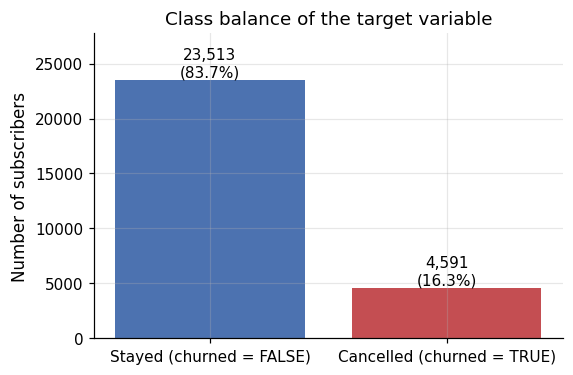

In [3]:
# Class distribution of the target ("churned", in the cancellation table)
print("Raw values of the target column 'churned':")
print(raw["cancellation"]["churned"].value_counts(dropna=False).to_string())

n_instances = int(raw["cancellation"]["subscriber_id"].nunique())
n_churn = int((raw["cancellation"]["churned"].str.strip().str.upper() == "TRUE").sum())
n_stay = n_instances - n_churn
prevalence = n_churn / n_instances
imbalance_ratio = n_stay / n_churn
majority_baseline_accuracy = n_stay / n_instances
print(f"\ninstances = {n_instances:,} | stayed = {n_stay:,} | churned = {n_churn:,}")
print(f"churn rate = {prevalence:.2%} | imbalance = {imbalance_ratio:.2f} : 1 | accuracy of 'always predict stay' = {majority_baseline_accuracy:.2%}")

fig, ax = plt.subplots(figsize=(5.5, 3.6))
bars = ax.bar(["Stayed (churned = FALSE)", "Cancelled (churned = TRUE)"], [n_stay, n_churn], color=["#4c72b0", "#c44e52"])
for b, v in zip(bars, [n_stay, n_churn]):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,}\n({v / n_instances:.1%})", ha="center", va="bottom")
ax.set_ylim(0, n_stay * 1.18)
ax.set_ylabel("Number of subscribers")
ax.set_title("Class balance of the target variable")
plt.show()

### 1.1 What was loaded

**Source.** STADIOchoice supplied three CSV tables and a README. All three describe the same subscribers and are linked by `subscriber_id`. The pack for this project contains only these three tables, and all three are relevant:

| Table | What it holds | Rows | Columns |
|---|---|---|---|
| `table1_subscription_billing.csv` | plan, price, start date, tenure, payment history | 28,188 | 9 |
| `table2_streaming_viewing_behaviour.csv` | watching, login and search behaviour, device | 28,104 | 7 |
| `table3_cancellation_retention.csv` | whether the subscriber cancelled (**the target**), cancellation details, retention offers | 28,104 | 6 |

**Number of instances.** The billing table has 28,188 rows, of which 84 are exact duplicates (removed in section 2). The other two tables have 28,104 rows each. After the duplicates are removed and the tables are joined, there is **one row per subscriber, so 28,104 instances**.

**Classes.** The target is `churned` (table 3):

* `FALSE`: the subscriber stayed: **23,513** subscribers (83.66%)
* `TRUE`: the subscriber cancelled during the observation window: **4,591** subscribers (16.34%)

**Imbalance proportion.** **5.12 : 1** (stayed : cancelled). This matters for every later decision:

* *Accuracy is misleading.* A model that always says "will stay" would be right 83.7% of the time while catching no churner at all. So the notebook judges models with ranking metrics (ROC-AUC, PR-AUC) and with precision and recall on the churn class.
* The split is **stratified** so every subset keeps the same 16.3% churn rate.
* Both models use `class_weight="balanced"` (as in SS2) so mistakes on the rarer class are not ignored.

**Why the CSV format is appropriate, and how it is used.** The client supplies one text table per kind of information, linked by a key (`subscriber_id`), and the data is small (about 84 thousand rows in total, roughly 4 MB). A plain CSV is human-readable and keeps the data exactly as supplied. A binary format such as Parquet would only pay off for much larger data. Each table has exactly one row per subscriber, so the tables are joined one-to-one on `subscriber_id` (checked in section 2). Reading every column as text first means that no type is guessed silently: each type is set and validated explicitly in the next section.

## 2. Dataset preprocessing

The aim of preprocessing is to turn the client's raw tables into a clean dataset that a model can learn from **without seeing anything it should not see**.

**Steps (and why)**

1. **Clean and join** (2.2): remove duplicate rows, standardise text, set data types, handle missing values and check the data for logical errors. The client's README warns that the data is deliberately messy, and wrong values would silently weaken or mislead the model.
2. **Build features that are known at a fixed prediction date** (2.3): so the model only uses information that would really be available when STADIOchoice has to decide whom to contact.
3. **Split into training (60%), validation (20%) and test (20%)** (2.4): *before* anything is learned from the data, so no information from the validation or test subscribers can reach the model.
4. **Audit for leakage using the training data only** (2.5): to find the columns that reveal the outcome.
5. **Choose the features and define the preprocessing pipeline** (2.6): one-hot encoding, scaling and median imputation, **fitted on the training set only** and then applied unchanged to the validation and test sets.

In [4]:
# ---- 2.2 Cleaning ------------------------------------------------------------------
billing, viewing, cancel = raw["billing"].copy(), raw["viewing"].copy(), raw["cancellation"].copy()
tables = {"billing": billing, "viewing": viewing, "cancellation": cancel}

# (a) exact duplicate rows (billing table)
n_dups = int(billing.duplicated().sum())
billing.drop_duplicates(inplace=True)
billing.reset_index(drop=True, inplace=True)
print(f"(a) Billing table: removed {n_dups} exact duplicate rows -> {len(billing):,} rows")
for name, t in tables.items():
    assert t["subscriber_id"].is_unique, f"{name}: subscriber_id is not unique"
assert set(billing.subscriber_id) == set(viewing.subscriber_id) == set(cancel.subscriber_id)
print("    subscriber_id is unique in every table and the three tables cover exactly the same subscribers")

# (b) inconsistent text (spaces, capital letters)
def clean_text(s):
    return s.str.strip().str.lower().str.replace(r"\s+", " ", regex=True)

text_cols = {"billing": ["plan_type", "payment_status", "upgrade_downgrade_history"],
             "viewing": ["device_type"], "cancellation": ["cancellation_reason"]}
rows = []
for tname, cols in text_cols.items():
    for c in cols:
        before = tables[tname][c].nunique()
        tables[tname][c] = clean_text(tables[tname][c])
        rows.append({"column": c, "distinct values before": before,
                     "distinct values after": tables[tname][c].nunique(),
                     "values after cleaning": ", ".join(sorted(tables[tname][c].dropna().unique()))})
print("\n(b) Text columns standardised (strip spaces, lower case, single spaces):")
display(pd.DataFrame(rows))

(a) Billing table: removed 84 exact duplicate rows -> 28,104 rows
    subscriber_id is unique in every table and the three tables cover exactly the same subscribers

(b) Text columns standardised (strip spaces, lower case, single spaces):


,column,distinct values before,distinct values after,values after cleaning
0,plan_type,17,4,"basic, premium, premium 4k, standard"
1,payment_status,12,3,"failed, pending, success"
2,upgrade_downgrade_history,3,3,"downgraded, no change, upgraded"
3,device_type,22,5,"mobile, smart tv, streaming stick, tablet, web"
4,cancellation_reason,5,5,"not enough content, not given, other, technical issues, too expensive"


In [5]:
# (c) data types: flags to 0/1, numbers to numeric, dates to datetime. Anything that cannot be converted is counted.
def to_flag(s):
    return s.str.strip().str.upper().map({"TRUE": 1, "FALSE": 0})

flag_cols = {"billing": ["free_trial_flag"], "viewing": ["zero_result_search_flag"],
             "cancellation": ["churned", "retention_offer_made", "retention_offer_accepted"]}
num_cols = {"billing": ["monthly_price", "tenure_months", "payment_failures_last_6_months"],
            "viewing": ["titles_watched_last_30_days", "total_watch_time_last_30_days_minutes",
                        "days_since_last_login", "search_count_last_30_days"]}
date_cols = {"billing": ["subscription_start_date"], "cancellation": ["cancellation_date"]}

conv = []
for tname, cols in flag_cols.items():
    for c in cols:
        new = to_flag(tables[tname][c])
        conv.append({"column": c, "converted to": "0/1 flag", "values that could not be converted": int(tables[tname][c].notna().sum() - new.notna().sum())})
        tables[tname][c] = new
for tname, cols in num_cols.items():
    for c in cols:
        new = pd.to_numeric(tables[tname][c], errors="coerce")
        conv.append({"column": c, "converted to": "number", "values that could not be converted": int(tables[tname][c].notna().sum() - new.notna().sum())})
        tables[tname][c] = new
for tname, cols in date_cols.items():
    for c in cols:
        new = pd.to_datetime(tables[tname][c], errors="coerce")
        conv.append({"column": c, "converted to": "date", "values that could not be converted": int(tables[tname][c].notna().sum() - new.notna().sum())})
        tables[tname][c] = new
print("(c) Data type conversion:")
display(pd.DataFrame(conv))
assert cancel["churned"].notna().all(), "the target must not have missing values"

# (d) missing values
miss = []
for tname, t in tables.items():
    for c in t.columns:
        n = int(t[c].isna().sum())
        if n:
            miss.append({"table": tname, "column": c, "missing": n, "% of rows": round(100 * n / len(t), 2)})
print("\n(d) Missing values before handling:")
display(pd.DataFrame(miss))
print("Handling: device_type is filled with 'unknown' and kept as its own category (about 3% of rows).")
print("          total_watch_time is left missing: that column is excluded from the model (see 2.5).")
print("          cancellation_date / cancellation_reason are blank for subscribers who did not cancel: expected, not an error.")
viewing["device_type"] = viewing["device_type"].fillna("unknown")

(c) Data type conversion:

(d) Missing values before handling:
Handling: device_type is filled with 'unknown' and kept as its own category (about 3% of rows).
          total_watch_time is left missing: that column is excluded from the model (see 2.5).
          cancellation_date / cancellation_reason are blank for subscribers who did not cancel: expected, not an error.


,column,converted to,values that could not be converted
0,free_trial_flag,0/1 flag,0
1,zero_result_search_flag,0/1 flag,0
2,churned,0/1 flag,0
3,retention_offer_made,0/1 flag,0
4,retention_offer_accepted,0/1 flag,0
5,monthly_price,number,0
6,tenure_months,number,0
7,payment_failures_last_6_months,number,0
8,titles_watched_last_30_days,number,0
9,total_watch_time_last_30_days_minutes,number,0


,table,column,missing,% of rows
0,viewing,total_watch_time_last_30_days_minutes,256,0.91
1,viewing,device_type,898,3.20
2,cancellation,cancellation_date,23513,83.66
3,cancellation,cancellation_reason,22314,79.40


In [6]:
# (e) join the three tables: exactly one row per subscriber
df = (billing.merge(viewing, on="subscriber_id", how="inner", validate="one_to_one")
             .merge(cancel, on="subscriber_id", how="inner", validate="one_to_one"))
assert len(df) == len(billing) == len(viewing) == len(cancel)
df["churned"] = df["churned"].astype(int)
print(f"(e) Joined dataset: {df.shape[0]:,} subscribers x {df.shape[1]} columns (one row per subscriber)")

# (f) logical checks on the joined data
def violations(mask):
    return int(mask.sum())

checks = pd.DataFrame([
    ("tenure_months below 0", violations(df.tenure_months < 0)),
    ("paid plan (not a free trial) with a price of 0 or less", violations((df.monthly_price <= 0) & (df.free_trial_flag == 0))),
    ("free trial with a price above 0", violations((df.monthly_price > 0) & (df.free_trial_flag == 1))),
    ("payment failures below 0", violations(df.payment_failures_last_6_months < 0)),
    ("days_since_last_login outside 0-365", violations((df.days_since_last_login < 0) | (df.days_since_last_login > 365))),
    ("negative titles / watch time / search counts", violations((df.titles_watched_last_30_days < 0) | (df.total_watch_time_last_30_days_minutes < 0) | (df.search_count_last_30_days < 0))),
    ("watch time above 0 but zero titles watched (inconsistent)", violations((df.total_watch_time_last_30_days_minutes > 0) & (df.titles_watched_last_30_days == 0))),
    ("titles watched above 0 but zero watch time (inconsistent)", violations((df.titles_watched_last_30_days > 0) & (df.total_watch_time_last_30_days_minutes == 0))),
    ("churned = 1 but no cancellation_date", violations((df.churned == 1) & df.cancellation_date.isna())),
    ("churned = 0 but has a cancellation_date", violations((df.churned == 0) & df.cancellation_date.notna())),
    ("cancellation_date earlier than subscription_start_date", violations(df.cancellation_date < df.subscription_start_date)),
    ("retention offer accepted but no offer made", violations((df.retention_offer_accepted == 1) & (df.retention_offer_made != 1))),
], columns=["logical check", "rows violating it"])
print("\n(f) Logical checks:")
display(checks)

print("Observation window (from the cancellation dates):",
      df.cancellation_date.min().date(), "to", df.cancellation_date.max().date())
print("Subscription start dates:", df.subscription_start_date.min().date(), "to", df.subscription_start_date.max().date())

(e) Joined dataset: 28,104 subscribers x 20 columns (one row per subscriber)

(f) Logical checks:
Observation window (from the cancellation dates): 2025-09-01 to 2026-08-31
Subscription start dates: 2021-06-01 to 2026-07-21


,logical check,rows violating it
0,tenure_months below 0,0
1,paid plan (not a free trial) with a price of 0 or less,0
2,free trial with a price above 0,0
3,payment failures below 0,0
4,days_since_last_login outside 0-365,0
5,negative titles / watch time / search counts,0
6,watch time above 0 but zero titles watched (inconsistent),2978
7,titles watched above 0 but zero watch time (inconsistent),825
8,churned = 1 but no cancellation_date,0
9,churned = 0 but has a cancellation_date,0


### 2.3 Features known at a fixed prediction date

All cancellations in the data happen between September 2025 and August 2026 (see the output above), so the observation window starts on **1 September 2025**. Imagine STADIOchoice making its decision on that day: it can use what it knows about each account on that day, not what happens afterwards.

From the subscription start date alone (a fact that never depends on the outcome) three features are built:

* `tenure_at_index_months`: months between the subscription start and 1 Sep 2025 (0 for people who joined later, because they were not yet customers);
* `joined_in_window`: 1 if the subscriber joined after 1 Sep 2025;
* `months_into_window`: how many months after 1 Sep 2025 they joined (0 for older subscribers).

This replaces the supplied `tenure_months`, which is **not** safe to use: for churners it is counted up to their cancellation date and for everyone else up to the extract date, so its value depends on the outcome (shown in 2.5).

In [7]:
df["tenure_at_index_months"] = ((INDEX_DATE - df["subscription_start_date"]).dt.days / 30.44).clip(lower=0)
df["joined_in_window"] = (df["subscription_start_date"] >= INDEX_DATE).astype(int)
df["months_into_window"] = ((df["subscription_start_date"] - INDEX_DATE).dt.days / 30.44).clip(lower=0)

assert df.cancellation_date.min() >= INDEX_DATE, "a cancellation happens before the observation window starts"
print(f"Subscribers who joined during the observation window: {df.joined_in_window.sum():,} ({df.joined_in_window.mean():.1%})")
display(df[["tenure_at_index_months", "joined_in_window", "months_into_window"]].describe().round(2))

Subscribers who joined during the observation window: 4,901 (17.4%)


,tenure_at_index_months,joined_in_window,months_into_window
count,28104.00,28104.00,28104.00
mean,21.08,0.17,0.91
std,16.56,0.38,2.36
min,0.00,0.00,0.00
25%,4.60,0.00,0.00
50%,20.17,0.00,0.00
75%,35.58,0.00,0.00
max,51.02,1.00,10.61


### 2.4 Train / validation / test split

The data is split **now**, before anything is learned from it.

* **Training set (60%)**: the only data the models learn from, and the only data used to fit preprocessing steps.
* **Validation set (20%)**: used to compare the two models and to set the decision threshold.
* **Test set (20%)**: kept untouched until the very end (section 4.6) to give one honest estimate of how the final model performs on subscribers it has never seen.

The split is **stratified on `churned`**, so each subset has the same churn rate, and uses the same seed (42) as SS2. A random split is used (as in SS2) because the client supplies one snapshot with one outcome per subscriber; a split by date would not be meaningful here.

In [8]:
TARGET = "churned"
y_all = df[TARGET]
idx_trainval, idx_test = train_test_split(df.index, test_size=0.20, stratify=y_all, random_state=SEED)
idx_train, idx_val = train_test_split(idx_trainval, test_size=0.25, stratify=y_all.loc[idx_trainval], random_state=SEED)  # 0.25 x 0.80 = 0.20

train, val, test = df.loc[idx_train].copy(), df.loc[idx_val].copy(), df.loc[idx_test].copy()
assert not (set(train.subscriber_id) & set(val.subscriber_id)) and not (set(train.subscriber_id) & set(test.subscriber_id)) \
       and not (set(val.subscriber_id) & set(test.subscriber_id)), "subsets overlap"

split_table = pd.DataFrame({
    "subscribers": [len(train), len(val), len(test)],
    "share of data": [f"{len(s) / len(df):.0%}" for s in (train, val, test)],
    "churners": [int(s[TARGET].sum()) for s in (train, val, test)],
    "churn rate": [f"{s[TARGET].mean():.2%}" for s in (train, val, test)],
}, index=["training", "validation", "test"])
display(split_table)

,subscribers,share of data,churners,churn rate
training,16862,60%,2755,16.34%
validation,5621,20%,918,16.33%
test,5621,20%,918,16.33%


### 2.5 Leakage audit (training data only)

The client's README warns that the engagement measures (`days_since_last_login`, `titles_watched_last_30_days`, `total_watch_time_last_30_days_minutes`) are measured up to the *extract date*. A subscriber who cancelled months earlier therefore looks "inactive" simply because they have **already left**. The model would be reading the *consequence* of churn, not an early warning of it. The same README notes that `tenure_months` is counted up to the cancellation date for churners.

A simple test shows this: take each feature on its own and see how well it alone separates churners from non-churners (**single-feature ROC-AUC**: 0.5 means no signal, 1.0 means a perfect separation). Genuine early-warning signals in churn data are weak to moderate. A single feature that separates the classes almost perfectly is a warning sign. This is computed on the **training set only**.

,feature,single-feature AUC,decision,reason
0,days_since_last_login,0.999,EXCLUDED: post-outcome,counts the days since the subscriber left
1,titles_watched_last_30_days,0.865,EXCLUDED: post-outcome,30-day window to the extract date
2,total_watch_time_last_30_days_minutes,0.841,EXCLUDED: post-outcome,30-day window to the extract date
3,tenure_months,0.672,EXCLUDED: post-outcome,counted to cancellation for churners
4,search_count_last_30_days,0.655,EXCLUDED: cautious choice,30-day window to the extract date
5,payment_failures_last_6_months,0.618,usable (known at prediction date),billing history
6,tenure_at_index_months,0.583,usable (known at prediction date),from start date
7,zero_result_search_flag,0.542,EXCLUDED: cautious choice,30-day window to the extract date
8,months_into_window,0.539,usable (known at prediction date),from start date
9,joined_in_window,0.538,usable (known at prediction date),from start date


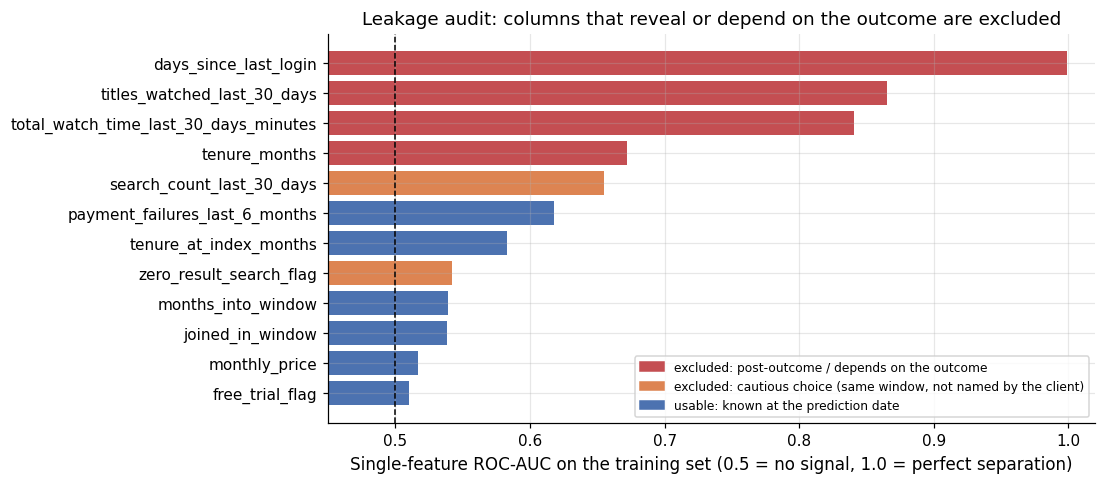

In [9]:
def directional_auc(x, y):
    m = x.notna()
    a = roc_auc_score(y[m], x[m])
    return max(a, 1 - a)          # direction does not matter for this audit

post_outcome = {   # reveal or depend on the outcome
    "days_since_last_login": "counts the days since the subscriber left",
    "titles_watched_last_30_days": "30-day window to the extract date",
    "total_watch_time_last_30_days_minutes": "30-day window to the extract date",
    "tenure_months": "counted to cancellation for churners",
}
cautious = {       # not named by the client, but measured in the same window (cautious choice, see 2.5)
    "search_count_last_30_days": "30-day window to the extract date",
    "zero_result_search_flag": "30-day window to the extract date",
}
suspect = {**post_outcome, **cautious}
safe = {"monthly_price": "account fact", "payment_failures_last_6_months": "billing history",
        "tenure_at_index_months": "from start date", "months_into_window": "from start date",
        "free_trial_flag": "account fact", "joined_in_window": "from start date"}

audit = pd.DataFrame(
    [(c, directional_auc(train[c], train[TARGET]), "EXCLUDED: post-outcome", why) for c, why in post_outcome.items()] +
    [(c, directional_auc(train[c], train[TARGET]), "EXCLUDED: cautious choice", why) for c, why in cautious.items()] +
    [(c, directional_auc(train[c], train[TARGET]), "usable (known at prediction date)", why) for c, why in safe.items()],
    columns=["feature", "single-feature AUC", "decision", "reason"]).sort_values("single-feature AUC", ascending=False).reset_index(drop=True)
audit["single-feature AUC"] = audit["single-feature AUC"].round(3)
display(audit)

fig, ax = plt.subplots(figsize=(9, 4.6))
plot_df = audit.sort_values("single-feature AUC")
palette = {"EXCLUDED: post-outcome": "#c44e52", "EXCLUDED: cautious choice": "#dd8452", "usable (known at prediction date)": "#4c72b0"}
colors = [palette[d] for d in plot_df["decision"]]
ax.barh(plot_df["feature"], plot_df["single-feature AUC"], color=colors)
ax.axvline(0.5, color="black", lw=1, ls="--")
ax.set_xlim(0.45, 1.02)
ax.set_xlabel("Single-feature ROC-AUC on the training set (0.5 = no signal, 1.0 = perfect separation)")
ax.set_title("Leakage audit: columns that reveal or depend on the outcome are excluded")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color="#c44e52", label="excluded: post-outcome / depends on the outcome"),
                   Patch(color="#dd8452", label="excluded: cautious choice (same window, not named by the client)"),
                   Patch(color="#4c72b0", label="usable: known at the prediction date")], loc="lower right", fontsize=8)
plt.show()

In [10]:
# Second diagnostic: does a column drift with HOW LONG AGO the subscriber left?  (churners only, training set only)
# A column that counts or records things *after* the subscriber has gone will change with the time since cancellation.
from scipy.stats import spearmanr

EXTRACT_DATE = df["cancellation_date"].max()   # assumption: the extract was taken at the end of the observation window
tr_churners = train[train[TARGET] == 1].copy()
tr_churners["months_since_cancellation"] = (EXTRACT_DATE - tr_churners["cancellation_date"]).dt.days / 30.44

drift_rows = []
for c in list(suspect) + ["payment_failures_last_6_months", "monthly_price"]:
    x = tr_churners[c]
    m = x.notna()
    rho, pval = spearmanr(x[m], tr_churners.loc[m, "months_since_cancellation"])
    drift_rows.append({"column": c, "Spearman rho with months since cancellation": round(float(rho), 3), "p-value": f"{pval:.1e}"})
drift = pd.DataFrame(drift_rows)
print(f"Churners in the training set: {len(tr_churners):,}. Assumed extract date: {EXTRACT_DATE.date()}")
display(drift)

# Is tenure_months counted to the cancellation date for churners?  Compare the two possible definitions.
ch_rows, stay_rows = train[train[TARGET] == 1], train[train[TARGET] == 0]
months = lambda end, start: (end - start).dt.days / 30.44
tenure_check = pd.DataFrame({
    "group": ["churners", "churners", "subscribers who stayed"],
    "tenure_months compared with": ["start -> cancellation date", "start -> extract date", "start -> extract date"],
    "mean absolute difference (months)": [
        (ch_rows["tenure_months"] - months(ch_rows["cancellation_date"], ch_rows["subscription_start_date"])).abs().mean(),
        (ch_rows["tenure_months"] - months(EXTRACT_DATE, ch_rows["subscription_start_date"])).abs().mean(),
        (stay_rows["tenure_months"] - months(EXTRACT_DATE, stay_rows["subscription_start_date"])).abs().mean()]}).round(2)
print("\nHow is tenure_months calculated? (a difference near 0 means that is the definition used)")
display(tenure_check)

Churners in the training set: 2,755. Assumed extract date: 2026-08-31

How is tenure_months calculated? (a difference near 0 means that is the definition used)


,column,Spearman rho with months since cancellation,p-value
0,days_since_last_login,0.985,0.0e+00
1,titles_watched_last_30_days,-0.039,4.0e-02
2,total_watch_time_last_30_days_minutes,-0.054,5.0e-03
3,tenure_months,0.057,2.9e-03
4,search_count_last_30_days,-0.017,3.8e-01
5,zero_result_search_flag,-0.019,3.3e-01
6,payment_failures_last_6_months,-0.015,4.2e-01
7,monthly_price,-0.003,8.5e-01


,group,tenure_months compared with,mean absolute difference (months)
0,churners,start -> cancellation date,0.51
1,churners,start -> extract date,6.06
2,subscribers who stayed,start -> extract date,0.50


**What the audit shows.** `days_since_last_login` alone reaches an AUC of **0.999**, which is almost perfect, and `titles_watched_last_30_days` and `total_watch_time_last_30_days_minutes` reach 0.865 and 0.841. No account or billing feature comes close: the best usable one, `payment_failures_last_6_months`, reaches only 0.618. This is exactly the leakage the client warned about: these columns describe what the subscriber did *after* deciding to leave.

**Tenure.** `tenure_months` has only a moderate AUC on its own (0.672), and it is excluded because of *how it is calculated*, not because of its AUC. The check above shows that for churners it matches the time from the start date to the **cancellation date** (average difference 0.51 months) and not the time to the extract date (6.06 months), while for subscribers who stayed it matches the time to the extract date (0.50 months). Because it is measured differently for churners and non-churners, its value depends on the outcome.

**A second check (drift with time since cancellation).** Among churners only, `days_since_last_login` rises almost one-for-one with how long ago the subscriber cancelled (Spearman rho = +0.98): it literally counts the days since they left, which is the signature of a post-outcome column. The two search columns do not show this signature (rho close to 0: -0.02 and -0.02), so they are the *least clearly* contaminated of the excluded columns. They are still excluded because they are measured in the same 30-day window that ends at the extract date, and nothing in the data lets us prove that churners' search activity was recorded before they decided to leave. This is the cautious choice, and section 4.8 puts a number on what it costs.

**Decision.** All columns that are measured over a window ending at the extract date, or counted up to the cancellation, are excluded. This also covers the two search columns, which the README does not name (see the second check above). Every column of the cancellation table (`cancellation_date`, `cancellation_reason`, `retention_offer_made`, `retention_offer_accepted`) is also excluded: these only exist once a subscriber has asked to cancel, so using them would again use the answer to predict the answer. `subscriber_id` is excluded because it carries no meaning. Section 4.8 measures how much leakage would have inflated the results.

**One assumption to confirm with the client:** the account and billing facts that are kept (plan, price, payment status, payment failures, upgrade/downgrade history, device) are treated as known before the subscriber decides to cancel. If any of them is recorded only at cancellation time, it would have to be removed as well.

In [11]:
decisions = pd.DataFrame([
    ("subscriber_id", "identifier", "excluded", "no meaning; would let a model memorise subscribers"),
    ("plan_type, monthly_price, free_trial_flag", "billing", "USED", "account facts known before the decision to cancel"),
    ("payment_status, payment_failures_last_6_months", "billing", "USED", "billing history; assumed known before cancelling (to confirm with client)"),
    ("upgrade_downgrade_history", "billing", "USED", "account history; assumed known before cancelling (to confirm with client)"),
    ("subscription_start_date", "billing", "USED (as 3 index-date features)", "a fixed fact; see 2.3"),
    ("tenure_months", "billing", "excluded", "counted to cancellation for churners, to the extract date for others"),
    ("device_type", "viewing", "USED", "stable characteristic of the account"),
    ("days_since_last_login, titles_watched_last_30_days, total_watch_time_last_30_days_minutes", "viewing", "excluded", "measured to the extract date: churners have already left (leakage)"),
    ("search_count_last_30_days, zero_result_search_flag", "viewing", "excluded", "same 30-day window to the extract date (conservative rule)"),
    ("churned", "cancellation", "TARGET", "what we predict"),
    ("cancellation_date, cancellation_reason, retention_offer_made, retention_offer_accepted", "cancellation", "excluded", "only exist once the subscriber asks to cancel (outcome-side information)"),
], columns=["column(s)", "table", "decision", "reason"])
display(decisions)

# ---- 2.6 Final feature set, outlier audit and preprocessing pipeline ---------------
CAT_FEATURES = ["plan_type", "payment_status", "upgrade_downgrade_history", "device_type"]
NUM_FEATURES = ["monthly_price", "payment_failures_last_6_months", "tenure_at_index_months", "months_into_window"]
BIN_FEATURES = ["free_trial_flag", "joined_in_window"]
FEATURES = CAT_FEATURES + NUM_FEATURES + BIN_FEATURES

# outlier audit: IQR fences are computed on the training set only
rows = []
for c in NUM_FEATURES:
    q1, q3 = train[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows.append({"feature": c, "min": round(train[c].min(), 2), "max": round(train[c].max(), 2),
                 "IQR lower fence": round(lo, 2), "IQR upper fence": round(hi, 2),
                 "rows outside fences": int(((train[c] < lo) | (train[c] > hi)).sum())})
print("\nOutlier audit (training set):")
display(pd.DataFrame(rows))

def make_preprocessor(scale, cat=None, num=None, binary=None):
    """Preprocessing that is FITTED ON THE TRAINING SET ONLY (it lives inside the model pipeline)."""
    cat = CAT_FEATURES if cat is None else cat
    num = NUM_FEATURES if num is None else num
    binary = BIN_FEATURES if binary is None else binary
    num_steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("scale", StandardScaler()))
    return ColumnTransformer([
        ("categorical", OneHotEncoder(handle_unknown="ignore"), cat),
        ("numeric", Pipeline(num_steps), num),
        ("binary", SimpleImputer(strategy="most_frequent"), binary)])

demo = make_preprocessor(scale=True).fit(train[FEATURES])
print("\nPreprocessor fitted on the training set only:")
print("  training matrix   :", demo.transform(train[FEATURES]).shape)
print("  validation matrix :", demo.transform(val[FEATURES]).shape, "(same columns, transformed with the training-set fit)")
print("  test matrix       :", demo.transform(test[FEATURES]).shape)
print("  model inputs      :", list(demo.get_feature_names_out()))


Outlier audit (training set):

Preprocessor fitted on the training set only:
  training matrix   : (16862, 22)
  validation matrix : (5621, 22) (same columns, transformed with the training-set fit)
  test matrix       : (5621, 22)
  model inputs      : ['categorical__plan_type_basic', 'categorical__plan_type_premium', 'categorical__plan_type_premium 4k', 'categorical__plan_type_standard', 'categorical__payment_status_failed', 'categorical__payment_status_pending', 'categorical__payment_status_success', 'categorical__upgrade_downgrade_history_downgraded', 'categorical__upgrade_downgrade_history_no change', 'categorical__upgrade_downgrade_history_upgraded', 'categorical__device_type_mobile', 'categorical__device_type_smart tv', 'categorical__device_type_streaming stick', 'categorical__device_type_tablet', 'categorical__device_type_unknown', 'categorical__device_type_web', 'numeric__monthly_price', 'numeric__payment_failures_last_6_months', 'numeric__tenure_at_index_months', 'numeric__mo

,column(s),table,decision,reason
0,subscriber_id,identifier,excluded,no meaning; would let a model memorise subscribers
1,"plan_type, monthly_price, free_trial_flag",billing,USED,account facts known before the decision to cancel
2,"payment_status, payment_failures_last_6_months",billing,USED,billing history; assumed known before cancelling (to confirm with client)
3,upgrade_downgrade_history,billing,USED,account history; assumed known before cancelling (to confirm with client)
4,subscription_start_date,billing,USED (as 3 index-date features),a fixed fact; see 2.3
5,tenure_months,billing,excluded,"counted to cancellation for churners, to the extract date for others"
6,device_type,viewing,USED,stable characteristic of the account
7,"days_since_last_login, titles_watched_last_30_days, total_watch_time_last_30_days_minutes",viewing,excluded,measured to the extract date: churners have already left (leakage)
8,"search_count_last_30_days, zero_result_search_flag",viewing,excluded,same 30-day window to the extract date (conservative rule)
9,churned,cancellation,TARGET,what we predict


,feature,min,max,IQR lower fence,IQR upper fence,rows outside fences
0,monthly_price,0.0,279.00,-51.0,349.00,0
1,payment_failures_last_6_months,0.0,4.00,-1.5,2.50,92
2,tenure_at_index_months,0.0,51.02,-41.2,81.54,0
3,months_into_window,0.0,10.61,0.0,0.00,2862


### 2.6 Why these preprocessing choices

* **One-hot encoding** for `plan_type`, `payment_status`, `upgrade_downgrade_history` and `device_type`. These are categories without a natural order, so numbering them (1, 2, 3...) would invent an order that does not exist. `handle_unknown="ignore"` means a category that appears only in the validation or test data cannot crash the pipeline.
* **Standard scaling for Logistic Regression only.** Logistic Regression is sensitive to the scale of its inputs (price in rand against failures counted 0-4), and scaled inputs also make its coefficients comparable. Random Forest splits on thresholds, so scaling changes nothing for it, and it receives the unscaled numbers.
* **Median imputation** is included for robustness. It is fitted on the training set only, and in the final feature set there is nothing left to impute.
* **No outlier capping.** In SS2 the IQR rule was used to cap extreme electricity-consumption values that were measurement outliers. Here the audit above shows that the rows flagged by the IQR rule are genuine, not errors. For `payment_failures_last_6_months`, a subscriber with 3 or 4 failed payments is a real subscriber, and that group is exactly the group likely to churn. For `months_into_window`, the IQR fence collapses to 0 because most subscribers joined before the observation window, so the flagged rows are simply the 17% who joined during it. Capping would destroy useful signal in both cases, so nothing is capped. All values are inside their valid ranges (checked in 2.2).
* **Everything is a pipeline.** Encoders, scalers and imputers live inside the model pipeline. Whenever the pipeline is fitted, it learns its statistics from the training rows it is given; when it predicts on validation or test rows it only applies them. This guarantees the *same* preprocessing is applied to the validation and test sets and that nothing leaks from them into training.

## 3. Model training

**Models and alignment with SS2.** The same two models that were built in SS2 are trained here, with the **same hyper-parameters and the same seed**:

| Model | Hyper-parameter | Value | Why this value |
|---|---|---|---|
| **Model 1: Logistic Regression** | `C` | 1.0 | Default regularisation strength, as in SS2. With about 17,000 training rows and about 20 inputs there is little risk of over-fitting, so a stronger penalty is not needed. |
| | `max_iter` | 1000 | Enough iterations for the solver to converge (checked below); the default of 100 can stop early. Same as SS2. |
| | `class_weight` | `"balanced"` | Churners are only about 16% of the data. Balanced weights make a missed churner count about five times more than a wrongly flagged loyal subscriber, so the model does not simply predict "stays". Same as SS2. |
| | `random_state` | 42 | Reproducible results. |
| **Model 2: Random Forest** | `n_estimators` | 300 | Enough trees for a stable averaged prediction (more trees cost time but do not cause over-fitting). Same as SS2. |
| | `max_depth` | 10 | Limits how complex each tree can become, to control over-fitting. Same as SS2. |
| | `criterion` | `"gini"` | Standard split quality measure for classification. Same as SS2. |
| | `class_weight` | `"balanced"` | Same reason as above. Same as SS2. |
| | `random_state`, `n_jobs` | 42, -1 | Reproducibility and speed only. |

**What is different from SS2, and why.** (1) The data: real client data instead of the public PowerCo data. (2) The features: leakage-controlled (section 2.5). (3) The split: a validation set is added so that choosing a model and a threshold never touches the test set.

**Training protocol.** (1) Five-fold stratified cross-validation on the **training set only** estimates performance and shows over-fitting before any validation data is used. (2) Each model is then fitted on the whole training set. (3) All training outputs (settings, cross-validation scores, training scores, fit times, model files, feature effects) are **saved to disk** in `experimental_results/` and `models/` for later analysis.

In [12]:
KEYS = ["LR", "RF"]
NAMES = {"LR": "Logistic Regression (Model 1)", "RF": "Random Forest (Model 2)"}
LR_PARAMS = dict(C=1.0, max_iter=1000, class_weight="balanced", random_state=SEED)
RF_PARAMS = dict(n_estimators=300, max_depth=10, criterion="gini", class_weight="balanced", random_state=SEED, n_jobs=-1)

def build_pipeline(key, cat=None, num=None, binary=None, rf_overrides=None):
    if key == "LR":
        return Pipeline([("pre", make_preprocessor(True, cat, num, binary)), ("model", LogisticRegression(**LR_PARAMS))])
    params = {**RF_PARAMS, **(rf_overrides or {})}
    return Pipeline([("pre", make_preprocessor(False, cat, num, binary)), ("model", RandomForestClassifier(**params))])

X_train, y_train = train[FEATURES], train[TARGET]

# ---- 3.1 five-fold stratified cross-validation on the training set only ------------
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "precision": "precision", "recall": "recall", "f1": "f1"}
cv_tables = {}
for k in KEYS:
    t0 = time.time()
    res = cross_validate(build_pipeline(k), X_train, y_train, cv=cv, scoring=SCORING, return_train_score=True, n_jobs=1)
    cv_tables[k] = pd.DataFrame(res)
    print(f"{NAMES[k]}: 5-fold cross-validation done in {time.time() - t0:.1f}s")

rows = []
for k in KEYS:
    for m in SCORING:
        rows.append({"model": NAMES[k], "metric": m,
                     "training folds (mean)": round(cv_tables[k][f"train_{m}"].mean(), 3),
                     "held-out folds (mean)": round(cv_tables[k][f"test_{m}"].mean(), 3),
                     "held-out folds (sd)": round(cv_tables[k][f"test_{m}"].std(), 3)})
cv_summary = pd.DataFrame(rows)
print("\nCross-validation on the training set (precision / recall / F1 use the default 0.5 cut-off):")
display(cv_summary)

Logistic Regression (Model 1): 5-fold cross-validation done in 0.7s
Random Forest (Model 2): 5-fold cross-validation done in 14.7s

Cross-validation on the training set (precision / recall / F1 use the default 0.5 cut-off):


,model,metric,training folds (mean),held-out folds (mean),held-out folds (sd)
0,Logistic Regression (Model 1),roc_auc,0.685,0.682,0.015
1,Logistic Regression (Model 1),pr_auc,0.313,0.312,0.021
2,Logistic Regression (Model 1),precision,0.265,0.264,0.007
3,Logistic Regression (Model 1),recall,0.587,0.586,0.034
4,Logistic Regression (Model 1),f1,0.365,0.364,0.012
5,Random Forest (Model 2),roc_auc,0.806,0.658,0.011
6,Random Forest (Model 2),pr_auc,0.548,0.283,0.013
7,Random Forest (Model 2),precision,0.386,0.280,0.008
8,Random Forest (Model 2),recall,0.644,0.460,0.029
9,Random Forest (Model 2),f1,0.482,0.348,0.014


In [13]:
# ---- 3.2 fit both models on the whole training set and store the training outputs ---
fitted, train_log = {}, {}
for k in KEYS:
    t0 = time.time()
    pipe = build_pipeline(k)
    pipe.fit(X_train, y_train)
    fit_seconds = time.time() - t0
    p_train = pipe.predict_proba(X_train)[:, 1]
    fitted[k] = pipe
    train_log[k] = {
        "model": NAMES[k],
        "hyperparameters": LR_PARAMS if k == "LR" else {kk: vv for kk, vv in RF_PARAMS.items()},
        "fit_seconds": round(fit_seconds, 2),
        "n_training_rows": int(len(X_train)),
        "n_model_input_columns": int(len(pipe.named_steps["pre"].get_feature_names_out())),
        "training_roc_auc": round(float(roc_auc_score(y_train, p_train)), 4),
        "training_pr_auc": round(float(average_precision_score(y_train, p_train)), 4),
        "cv_mean_roc_auc": round(float(cv_tables[k]["test_roc_auc"].mean()), 4),
        "cv_mean_pr_auc": round(float(cv_tables[k]["test_pr_auc"].mean()), 4),
    }
    if k == "LR":
        train_log[k]["solver_iterations"] = int(pipe.named_steps["model"].n_iter_[0])
        train_log[k]["converged"] = bool(pipe.named_steps["model"].n_iter_[0] < LR_PARAMS["max_iter"])
    print(f"{NAMES[k]}: fitted in {fit_seconds:.1f}s | training ROC-AUC {train_log[k]['training_roc_auc']:.3f} "
          f"vs held-out CV ROC-AUC {train_log[k]['cv_mean_roc_auc']:.3f}")
print("Logistic Regression converged:", train_log["LR"]["converged"], f"({train_log['LR']['solver_iterations']} iterations of {LR_PARAMS['max_iter']})")

# model files
model_paths = {}
for k, fname in {"LR": "ss3_logistic_regression.joblib", "RF": "ss3_random_forest.joblib"}.items():
    joblib.dump(fitted[k], MODELS_DIR / fname, compress=3)
    model_paths[k] = str(MODELS_DIR / fname)

# what each model learned (kept for later analysis)
feat_names = list(fitted["LR"].named_steps["pre"].get_feature_names_out())
effects = pd.DataFrame({"model_input": feat_names,
                        "logistic_regression_coefficient": fitted["LR"].named_steps["model"].coef_[0],
                        "random_forest_impurity_importance": fitted["RF"].named_steps["model"].feature_importances_})
effects.to_csv(RESULTS_DIR / "ss3_training_feature_effects.csv", index=False)
cv_summary.to_csv(RESULTS_DIR / "ss3_cv_summary.csv", index=False)
pd.concat({NAMES[k]: cv_tables[k] for k in KEYS}, names=["model", "fold"]).to_csv(RESULTS_DIR / "ss3_cv_fold_scores.csv")

training_log = {
    "run_timestamp_utc": pd.Timestamp.now("UTC").strftime("%Y-%m-%d %H:%M:%S"),
    "seed": SEED, "index_date": str(INDEX_DATE.date()),
    "library_versions": {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__, "scikit_learn": sklearn.__version__},
    "split": {"train": len(train), "validation": len(val), "test": len(test), "stratified_on": TARGET},
    "features_used": {"categorical": CAT_FEATURES, "numeric": NUM_FEATURES, "binary": BIN_FEATURES},
    "models": train_log, "model_files": model_paths,
}
(RESULTS_DIR / "ss3_training_log.json").write_text(json.dumps(training_log, indent=2))

saved = sorted(p for p in list(RESULTS_DIR.glob("ss3_*")) + list(MODELS_DIR.glob("ss3_*")) if p.is_file())
print("\nTraining outputs stored for later analysis:")
display(pd.DataFrame({"file": [str(p) for p in saved], "size (KB)": [round(p.stat().st_size / 1024, 1) for p in saved]}))
assert all(p.stat().st_size < 25 * 1024 * 1024 for p in saved), "a file is larger than GitHub's 25 MB browser-upload limit"

Logistic Regression (Model 1): fitted in 0.1s | training ROC-AUC 0.685 vs held-out CV ROC-AUC 0.682
Random Forest (Model 2): fitted in 2.3s | training ROC-AUC 0.791 vs held-out CV ROC-AUC 0.658
Logistic Regression converged: True (17 iterations of 1000)

Training outputs stored for later analysis:


,file,size (KB)
0,experimental_results/ss3_cv_fold_scores.csv,2.7
1,experimental_results/ss3_cv_summary.csv,0.6
2,experimental_results/ss3_training_feature_effects.csv,1.7
3,experimental_results/ss3_training_log.json,1.8
4,models/ss3_logistic_regression.joblib,2.3
5,models/ss3_random_forest.joblib,6762.2


In [14]:
# ---- 3.3 Fairness check on the Random Forest settings (training-set cross-validation only) ----
# The SS2 settings are kept for alignment. This check asks: would a more regularised forest change the story?
rows = []
for leaf in [1, 20, 50, 100]:
    scores = cross_validate(build_pipeline("RF", rf_overrides={"min_samples_leaf": leaf}), X_train, y_train, cv=cv,
                            scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision"}, n_jobs=1)
    rows.append({"model": "Random Forest", "min_samples_leaf": leaf + 0 if leaf > 1 else 1,
                 "note": "SS2 setting (default)" if leaf == 1 else "more regularised",
                 "CV ROC-AUC": round(scores["test_roc_auc"].mean(), 3), "CV PR-AUC": round(scores["test_pr_auc"].mean(), 3)})
rows.append({"model": "Logistic Regression", "min_samples_leaf": "-", "note": "SS2 setting",
             "CV ROC-AUC": round(cv_tables["LR"]["test_roc_auc"].mean(), 3), "CV PR-AUC": round(cv_tables["LR"]["test_pr_auc"].mean(), 3)})
rf_sensitivity = pd.DataFrame(rows)
display(rf_sensitivity)

,model,min_samples_leaf,note,CV ROC-AUC,CV PR-AUC
0,Random Forest,1,SS2 setting (default),0.658,0.283
1,Random Forest,20,more regularised,0.677,0.301
2,Random Forest,50,more regularised,0.677,0.303
3,Random Forest,100,more regularised,0.677,0.300
4,Logistic Regression,-,SS2 setting,0.682,0.312


**Reading the training results.**

* **Over-fitting.** The Random Forest with the SS2 settings scores a training ROC-AUC of 0.791 but only 0.658 on held-out folds (a gap of 0.133): it partly memorises the training subscribers. Logistic Regression shows a gap of only 0.003 (training 0.685 against 0.682 held out).
* **Fairness check (3.3).** Making the forest more regularised lifts its cross-validated ROC-AUC from 0.658 to at most 0.677, which is still not clearly better than Logistic Regression's 0.682. So the Random Forest is not simply "badly tuned": with leakage-free features the genuine signal is small and mostly simple (additive), and a more complex model has little extra to find. The SS2 settings are kept for both models so that the comparison stays aligned with SS2.
* All training outputs are saved (see the table of files above).

## 4. Model validation

The trained models are now applied to subscribers they have **never seen**, and metrics are calculated to judge how well they work for the business problem.

**Protocol (fair validation without leakage)**

1. **Same preprocessing, learned from training only.** The fitted pipelines apply the training-set encoders, scalers and imputers to the validation and test rows, so no statistic is ever learned from them.
2. **Validation set** (20%) is used to compare the two models and to set the decision threshold. **Test set** (20%) is used once, at the end (4.6), and nothing is changed after seeing it.
3. **Metrics suited to imbalanced churn data.** ROC-AUC and PR-AUC measure how well the model *ranks* subscribers by risk (PR-AUC's no-skill baseline equals the churn rate). Precision, recall, F1 and lift measure what happens at the decision threshold. Accuracy is reported only to show that it is misleading here.
4. **Confidence intervals.** Every metric has a 95% bootstrap confidence interval ({N_BOOT} resamples of the evaluation set). The two models are compared with a *paired* bootstrap (same resamples for both), which tells us whether a difference is real or could be chance.
5. **Business link.** STADIOchoice wants to stop sending discounts to everyone who clicks "cancel" and to catch at-risk subscribers early. A retention team can only contact a limited number of people, so the decision threshold is set so that the **top 20% highest-risk subscribers are contacted** (`CONTACT_FRACTION`). The key business questions are then: *of all churners, what share is inside that top 20% (recall / capture rate), and how many times better is that than contacting 20% at random (lift)?* The threshold is set from the **validation scores only** and is then fixed for the test set.

In [15]:
# ---- 4.1 helper functions ------------------------------------------------------------
y_val = val[TARGET].to_numpy()
y_test = test[TARGET].to_numpy()
proba = {"val": {k: fitted[k].predict_proba(val[FEATURES])[:, 1] for k in KEYS},
         "test": {k: fitted[k].predict_proba(test[FEATURES])[:, 1] for k in KEYS}}

def op_threshold(scores, fraction):
    """Score above which the top `fraction` of subscribers fall."""
    return float(np.quantile(scores, 1 - fraction))

def point_metrics(y, p, thr):
    pred = p >= thr
    tp = int(np.sum(pred & (y == 1))); fp = int(np.sum(pred & (y == 0)))
    fn = int(np.sum(~pred & (y == 1))); tn = int(np.sum(~pred & (y == 0)))
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    return {"precision": precision, "recall": recall, "f1": f1, "lift": precision / y.mean(),
            "flagged_share": float(pred.mean()), "accuracy": (tp + tn) / len(y),
            "balanced_accuracy": 0.5 * (recall + tn / (tn + fp)), "tp": tp, "fp": fp, "fn": fn, "tn": tn}

def all_metrics(y, p, thr):
    d = {"roc_auc": float(roc_auc_score(y, p)), "pr_auc": float(average_precision_score(y, p))}
    d.update(point_metrics(y, p, thr))
    return d

def bootstrap(y, p_by_model, thr_by_model, n_boot=N_BOOT, seed=SEED):
    """Paired bootstrap: the same resampled subscribers are used for every model."""
    rng = np.random.default_rng(seed)
    draws = {k: [] for k in p_by_model}
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() == y[i].max():
            continue
        for k in p_by_model:
            draws[k].append(all_metrics(y[i], p_by_model[k][i], thr_by_model[k]))
    return {k: pd.DataFrame(v) for k, v in draws.items()}

def fmt(est, lo, hi, nd=3):
    return f"{est:.{nd}f} [{lo:.{nd}f}, {hi:.{nd}f}]"

TOP = int(CONTACT_FRACTION * 100)
METRIC_LABELS = {"roc_auc": "ROC-AUC (ranking quality)", "pr_auc": "PR-AUC (ranking quality)",
                 "precision": f"Precision, top {TOP}% contacted", "recall": f"Recall (share of churners caught), top {TOP}% contacted",
                 "f1": f"F1-score, top {TOP}% contacted", "lift": f"Lift vs random targeting, top {TOP}% contacted",
                 "accuracy": f"Accuracy, top {TOP}% contacted (misleading)"}

def metric_table(est, boot, prevalence):
    rows = []
    baseline = {"roc_auc": 0.5, "pr_auc": prevalence, "precision": prevalence, "recall": CONTACT_FRACTION,
                "f1": 2 * prevalence * CONTACT_FRACTION / (prevalence + CONTACT_FRACTION), "lift": 1.0,
                "accuracy": 1 - prevalence}
    for m, label in METRIC_LABELS.items():
        row = {"metric": label}
        for k in KEYS:
            lo, hi = np.percentile(boot[k][m], [2.5, 97.5])
            row[NAMES[k]] = fmt(est[k][m], lo, hi)
        row["no-skill baseline"] = f"{baseline[m]:.3f}"
        rows.append(row)
    return pd.DataFrame(rows).set_index("metric")

# ---- 4.2 decision threshold from the VALIDATION scores only --------------------------
thr = {k: op_threshold(proba["val"][k], CONTACT_FRACTION) for k in KEYS}
print(f"Decision threshold = score above which the top {TOP}% of validation subscribers fall (no labels used):")
for k in KEYS:
    print(f"  {NAMES[k]}: {thr[k]:.4f}")

# ---- 4.3 validation metrics with bootstrap confidence intervals ----------------------
t0 = time.time()
boot_val = bootstrap(y_val, proba["val"], thr)
est_val = {k: all_metrics(y_val, proba["val"][k], thr[k]) for k in KEYS}
print(f"\nValidation set: {len(y_val):,} subscribers, churn rate {y_val.mean():.2%}  (bootstrap took {time.time() - t0:.0f}s)")
val_table = metric_table(est_val, boot_val, y_val.mean())
display(val_table)

Decision threshold = score above which the top 20% of validation subscribers fall (no labels used):
  Logistic Regression (Model 1): 0.5986
  Random Forest (Model 2): 0.5499

Validation set: 5,621 subscribers, churn rate 16.33%  (bootstrap took 10s)


,Logistic Regression (Model 1),Random Forest (Model 2),no-skill baseline
metric,,,
ROC-AUC (ranking quality),"0.693 [0.672, 0.712]","0.667 [0.646, 0.685]",0.500
PR-AUC (ranking quality),"0.317 [0.287, 0.350]","0.279 [0.255, 0.309]",0.163
"Precision, top 20% contacted","0.322 [0.293, 0.351]","0.308 [0.282, 0.334]",0.163
"Recall (share of churners caught), top 20% contacted","0.394 [0.361, 0.425]","0.377 [0.344, 0.408]",0.200
"F1-score, top 20% contacted","0.354 [0.325, 0.381]","0.339 [0.312, 0.364]",0.180
"Lift vs random targeting, top 20% contacted","1.970 [1.818, 2.113]","1.883 [1.745, 2.016]",1.000
"Accuracy, top 20% contacted (misleading)","0.765 [0.753, 0.776]","0.760 [0.748, 0.770]",0.837


### 4.4 Choosing the final model (rule fixed before looking at the results)

SS2 chose Logistic Regression, and the SS2 feedback questioned whether Random Forest should have been chosen instead. Rather than argue, the choice is left to the evidence with a rule that is written down **before** the comparison is run:

> *Random Forest replaces the SS2 choice (Logistic Regression) only if its PR-AUC on the validation set is better by an amount whose 95% paired-bootstrap interval lies entirely above zero. Otherwise there is no reliable difference, and the simpler, more explainable Logistic Regression is kept.*

PR-AUC is the primary criterion because it is the ranking metric that is most sensitive to the minority (churn) class. ROC-AUC differences are reported as supporting evidence.

In [16]:
diff = boot_val["RF"] - boot_val["LR"]
d_pr = np.percentile(diff["pr_auc"], [2.5, 97.5])
d_roc = np.percentile(diff["roc_auc"], [2.5, 97.5])
est_d_pr = est_val["RF"]["pr_auc"] - est_val["LR"]["pr_auc"]
est_d_roc = est_val["RF"]["roc_auc"] - est_val["LR"]["roc_auc"]
RF_RELIABLY_BETTER = bool(d_pr[0] > 0)
LR_RELIABLY_BETTER = bool(d_pr[1] < 0)
FINAL = "RF" if RF_RELIABLY_BETTER else "LR"

print("Paired bootstrap on the validation set: difference (Random Forest minus Logistic Regression)")
print(f"  PR-AUC : {est_d_pr:+.4f}   95% CI [{d_pr[0]:+.4f}, {d_pr[1]:+.4f}]")
print(f"  ROC-AUC: {est_d_roc:+.4f}   95% CI [{d_roc[0]:+.4f}, {d_roc[1]:+.4f}]")
if RF_RELIABLY_BETTER:
    print("-> Random Forest is reliably better. FINAL MODEL = Random Forest.")
elif LR_RELIABLY_BETTER:
    print("-> Logistic Regression is reliably better. FINAL MODEL = Logistic Regression (the SS2 choice).")
else:
    print("-> No reliable difference. FINAL MODEL = Logistic Regression (the SS2 choice: simpler and more explainable).")
print("FINAL MODEL:", NAMES[FINAL])

Paired bootstrap on the validation set: difference (Random Forest minus Logistic Regression)
  PR-AUC : -0.0383   95% CI [-0.0582, -0.0185]
  ROC-AUC: -0.0261   95% CI [-0.0370, -0.0154]
-> Logistic Regression is reliably better. FINAL MODEL = Logistic Regression (the SS2 choice).
FINAL MODEL: Logistic Regression (Model 1)


In [17]:
# ---- 4.5 what the contact budget buys on the validation set ------------------------------
fractions = [0.05, 0.10, 0.20, 0.30, 0.50]
def capture_table(y, p_by_model, thr_source):
    rows = []
    for f in fractions:
        row = {"share of subscribers contacted": f"{f:.0%}"}
        for k in KEYS:
            t = op_threshold(thr_source[k], f)
            pm = point_metrics(y, p_by_model[k], t)
            row[f"{k} churners caught"] = f"{pm['recall']:.1%}"
            row[f"{k} precision"] = f"{pm['precision']:.1%}"
            row[f"{k} lift"] = f"{pm['lift']:.2f}x"
        rows.append(row)
    return pd.DataFrame(rows).set_index("share of subscribers contacted")

print("Validation set (thresholds and scores both from validation). LR = Logistic Regression, RF = Random Forest.")
print("'churners caught' = recall; contacting people at random would catch the same share as the share contacted (lift 1.0x).")
display(capture_table(y_val, proba["val"], proba["val"]))

Validation set (thresholds and scores both from validation). LR = Logistic Regression, RF = Random Forest.
'churners caught' = recall; contacting people at random would catch the same share as the share contacted (lift 1.0x).


,LR churners caught,LR precision,LR lift,RF churners caught,RF precision,RF lift
share of subscribers contacted,,,,,,
5%,13.8%,45.0%,2.76x,11.3%,36.9%,2.26x
10%,22.8%,37.1%,2.27x,20.3%,33.0%,2.02x
20%,39.4%,32.2%,1.97x,37.7%,30.8%,1.88x
30%,53.4%,29.0%,1.78x,49.2%,26.8%,1.64x
50%,73.0%,23.8%,1.46x,70.3%,22.9%,1.40x


### 4.6 Final evaluation on the test set (used once)

The decision thresholds from the validation set are applied **unchanged**. Nothing is re-tuned after this point.

In [18]:
t0 = time.time()
boot_test = bootstrap(y_test, proba["test"], thr)          # thresholds come from the validation set
est_test = {k: all_metrics(y_test, proba["test"][k], thr[k]) for k in KEYS}
print(f"Test set: {len(y_test):,} subscribers, churn rate {y_test.mean():.2%}  (bootstrap took {time.time() - t0:.0f}s)")
print(f"Final model chosen in 4.4: {NAMES[FINAL]}\n")
test_table = metric_table(est_test, boot_test, y_test.mean())
display(test_table)

cm_rows = []
for k in KEYS:
    e = est_test[k]
    cm_rows.append({"model": NAMES[k], "true negatives": e["tn"], "false positives": e["fp"], "false negatives": e["fn"], "true positives": e["tp"],
                    "share of subscribers flagged": f"{e['flagged_share']:.1%}"})
print("\nConfusion counts on the test set at the decision threshold:")
display(pd.DataFrame(cm_rows).set_index("model"))

print(f"\nTest set, what the contact budget buys (thresholds taken from the VALIDATION set at each budget):")
fr_rows = []
for f in fractions:
    row = {"share of subscribers contacted": f"{f:.0%}"}
    for k in KEYS:
        t = op_threshold(proba["val"][k], f)
        pm = point_metrics(y_test, proba["test"][k], t)
        row[f"{k} churners caught"] = f"{pm['recall']:.1%}"
        row[f"{k} precision"] = f"{pm['precision']:.1%}"
        row[f"{k} lift"] = f"{pm['lift']:.2f}x"
    fr_rows.append(row)
display(pd.DataFrame(fr_rows).set_index("share of subscribers contacted"))

Test set: 5,621 subscribers, churn rate 16.33%  (bootstrap took 10s)
Final model chosen in 4.4: Logistic Regression (Model 1)


Confusion counts on the test set at the decision threshold:

Test set, what the contact budget buys (thresholds taken from the VALIDATION set at each budget):


,Logistic Regression (Model 1),Random Forest (Model 2),no-skill baseline
metric,,,
ROC-AUC (ranking quality),"0.671 [0.652, 0.690]","0.649 [0.630, 0.668]",0.500
PR-AUC (ranking quality),"0.286 [0.264, 0.315]","0.265 [0.244, 0.291]",0.163
"Precision, top 20% contacted","0.314 [0.288, 0.341]","0.292 [0.265, 0.320]",0.163
"Recall (share of churners caught), top 20% contacted","0.392 [0.362, 0.425]","0.345 [0.314, 0.376]",0.200
"F1-score, top 20% contacted","0.348 [0.324, 0.375]","0.316 [0.291, 0.342]",0.180
"Lift vs random targeting, top 20% contacted","1.920 [1.789, 2.061]","1.786 [1.642, 1.932]",1.000
"Accuracy, top 20% contacted (misleading)","0.761 [0.749, 0.772]","0.756 [0.744, 0.767]",0.837


,true negatives,false positives,false negatives,true positives,share of subscribers flagged
model,,,,,
Logistic Regression (Model 1),3915,788,558,360,20.4%
Random Forest (Model 2),3933,770,601,317,19.3%


,LR churners caught,LR precision,LR lift,RF churners caught,RF precision,RF lift
share of subscribers contacted,,,,,,
5%,13.2%,39.0%,2.39x,12.6%,35.5%,2.17x
10%,22.5%,34.2%,2.10x,19.8%,30.2%,1.85x
20%,39.2%,31.4%,1.92x,34.5%,29.2%,1.79x
30%,49.3%,27.3%,1.67x,47.7%,26.3%,1.61x
50%,69.4%,22.6%,1.39x,66.9%,21.7%,1.33x


In [19]:
# ---- 4.7 save all validation and test results ------------------------------------------------
def summarise(est, boot):
    out = {}
    for k in KEYS:
        out[NAMES[k]] = {m: {"estimate": round(float(est[k][m]), 4),
                             "ci95_low": round(float(np.percentile(boot[k][m], 2.5)), 4),
                             "ci95_high": round(float(np.percentile(boot[k][m], 97.5)), 4)}
                         for m in METRIC_LABELS}
        out[NAMES[k]]["confusion"] = {c: int(est[k][c]) for c in ("tp", "fp", "fn", "tn")}
    return out

results = {
    "final_model": NAMES[FINAL],
    "selection_rule": "Random Forest replaces Logistic Regression only if the 95% paired-bootstrap CI of the validation PR-AUC difference lies above zero",
    "validation_difference_RF_minus_LR": {"pr_auc": {"estimate": round(float(est_d_pr), 4), "ci95": [round(float(d_pr[0]), 4), round(float(d_pr[1]), 4)]},
                                           "roc_auc": {"estimate": round(float(est_d_roc), 4), "ci95": [round(float(d_roc[0]), 4), round(float(d_roc[1]), 4)]}},
    "contact_fraction": CONTACT_FRACTION, "decision_thresholds_from_validation": {NAMES[k]: round(thr[k], 5) for k in KEYS},
    "bootstrap_resamples": N_BOOT, "seed": SEED,
    "validation": summarise(est_val, boot_val), "test": summarise(est_test, boot_test),
}
(RESULTS_DIR / "ss3_validation_results.json").write_text(json.dumps(results, indent=2))
val_table.to_csv(RESULTS_DIR / "ss3_validation_metrics.csv")
test_table.to_csv(RESULTS_DIR / "ss3_test_metrics.csv")
print("Saved: experimental_results/ss3_validation_results.json, ss3_validation_metrics.csv, ss3_test_metrics.csv")

Saved: experimental_results/ss3_validation_results.json, ss3_validation_metrics.csv, ss3_test_metrics.csv


### 4.8 How much would leakage have inflated the results? (illustration only)

To show why the audit in 2.5 matters, the same two models are trained on the training set with extra columns added and evaluated on the **validation** set. These results are **not** used to choose a model, and the leaky version must never be used in practice; the point is only to show what the leaked columns would have done.

* **A. Final features** (leakage-controlled), used everywhere else in this notebook.
* **B. A plus the two search columns** (30-day window to the extract date).
* **C. A plus all engagement columns and the supplied `tenure_months`** (leaky).

In [20]:
extra_search = ["search_count_last_30_days"]
extra_search_bin = ["zero_result_search_flag"]
extra_leaky = ["titles_watched_last_30_days", "total_watch_time_last_30_days_minutes", "days_since_last_login", "tenure_months"]
sets = {
    "A. final features (leakage-controlled)": dict(num=NUM_FEATURES, binary=BIN_FEATURES),
    "B. A + search columns": dict(num=NUM_FEATURES + extra_search, binary=BIN_FEATURES + extra_search_bin),
    "C. A + engagement + tenure_months (LEAKY)": dict(num=NUM_FEATURES + extra_search + extra_leaky, binary=BIN_FEATURES + extra_search_bin),
}
rows = []
for label, spec in sets.items():
    cols = CAT_FEATURES + spec["num"] + spec["binary"]
    row = {"feature set": label}
    for k in KEYS:
        p = build_pipeline(k, cat=CAT_FEATURES, num=spec["num"], binary=spec["binary"]).fit(train[cols], y_train)
        pv = p.predict_proba(val[cols])[:, 1]
        row[f"{k} ROC-AUC"] = round(roc_auc_score(y_val, pv), 3)
        row[f"{k} PR-AUC"] = round(average_precision_score(y_val, pv), 3)
    rows.append(row)
leak_demo = pd.DataFrame(rows).set_index("feature set")
display(leak_demo)
leak_demo.to_csv(RESULTS_DIR / "ss3_leakage_illustration.csv")

,LR ROC-AUC,LR PR-AUC,RF ROC-AUC,RF PR-AUC
feature set,,,,
A. final features (leakage-controlled),0.693,0.317,0.667,0.279
B. A + search columns,0.729,0.356,0.710,0.323
C. A + engagement + tenure_months (LEAKY),0.999,0.998,0.998,0.996


### 4.9 What the validation results mean for STADIOchoice

**Which model.** Logistic Regression (Model 1) is the final model. On the validation set the Random Forest minus Logistic Regression difference in PR-AUC is -0.038 (95% interval -0.058 to -0.018), and in ROC-AUC -0.026 (interval -0.037 to -0.015). The Logistic Regression is reliably better. Combined with the training results in section 3 (the Random Forest over-fits and a more regularised forest does no better), the evidence for this client data does not support replacing the SS2 choice.

**How good is it, honestly?** On the unseen test set the final model has a ROC-AUC of 0.671 (95% interval 0.652 to 0.690) and a PR-AUC of 0.286 (interval 0.264 to 0.315) against a no-skill PR-AUC of 0.163. The model is clearly better than guessing, but it is a **modest** model, not an accurate one. That is expected for a leakage-free model that only knows account and billing facts.

**What it buys the business.** If the retention team contacts the 20% of subscribers the model ranks as most at risk, it reaches **39.2% of the subscribers who go on to cancel** (95% interval 36.2% to 42.5%), which is **1.92 times better than contacting 20% at random** (interval 1.79 to 2.06). In other words, for every 100 churners the offers reach about 39 of them while only 20% of subscribers are contacted, instead of the about 20 that random targeting would reach. Precision at this budget is 31.4%: most contacted subscribers would not have cancelled, so offers must be cheap enough to give to loyal subscribers too (the larger the contact budget, the more churners are caught but the more offers are wasted; see the tables in 4.5 and 4.6).

**Why accuracy is not reported as a headline.** Accuracy at this threshold is 76.1%. It looks fine only because most subscribers stay; it says nothing about how many churners are caught.

**What leakage would have done (4.8).** With the leaky columns added, the same models reach a validation ROC-AUC of 0.999 (Logistic Regression) and 0.998 (Random Forest), against 0.693 and 0.667 for the honest feature set. A result that high would look impressive, but it would be worthless in practice, because those columns only reveal who has *already* left.

**What the cautious choice on the search columns costs (4.8).** Adding the two search columns would raise the validation ROC-AUC of Logistic Regression from 0.693 to 0.729. Part of that gain may be real early-warning signal and part may be churners who simply stopped searching after leaving; the data cannot tell us which. If STADIOchoice confirms that these columns were recorded *before* the cancellation decision, adding them is the cheapest first improvement.

**Limitations and what we would ask the client for.**

* The supplied data is **one snapshot taken at the extract date**. A true early-warning model needs features recorded *as at a fixed date before* the outcome (for example the state of every account on 1 September 2025, with the outcome observed over the following months). We would ask STADIOchoice to re-extract the viewing and engagement data on that basis; engagement is often among the strongest early signals of churn, and it is exactly what had to be removed here.
* The threshold rests on the assumption that the team can contact 20% of subscribers. The tables in 4.5 and 4.6 let the business pick the budget that suits its offer costs.
* The scores are ranking scores, not probabilities: `class_weight="balanced"` inflates them (see the calibration plot in section 5), so they should not be read as "chance of cancelling".
* The assumption that the kept billing columns are known *before* a subscriber decides to cancel should be confirmed with the client (section 2.5).

## 5. Results visualisation

The graphs below show the results for **training** data (cross-validation and learning curves, which show whether a model over-fits) and for **unseen** data (validation and test sets: ranking curves, what the contact budget buys, errors, what drives the predictions, and how trustworthy the scores are). All figures are also saved to `experimental_results/` (files `ss3_fig*.png`).

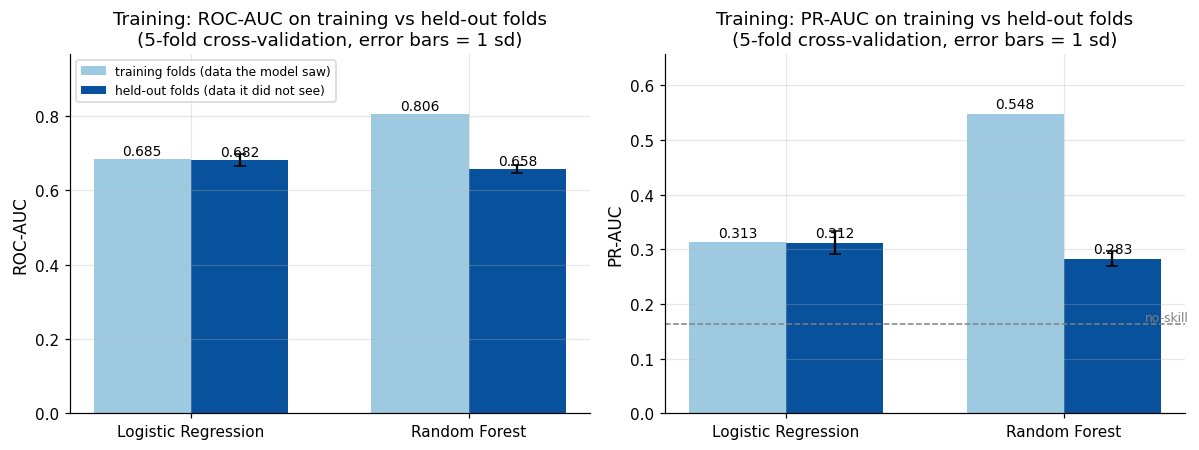

In [21]:
COLORS = {"LR": "#1f77b4", "RF": "#e07b00"}
SHORT = {"LR": "Logistic Regression", "RF": "Random Forest"}
def save_fig(fig, name):
    fig.savefig(FIG_DIR / name, dpi=130, bbox_inches="tight")

# ---- 5.1 TRAINING: cross-validation, seen vs unseen folds --------------------------------
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (m, label) in zip(axes, [("roc_auc", "ROC-AUC"), ("pr_auc", "PR-AUC")]):
    x = np.arange(len(KEYS)); w = 0.35
    tr = [cv_tables[k][f"train_{m}"].mean() for k in KEYS]
    te = [cv_tables[k][f"test_{m}"].mean() for k in KEYS]
    te_sd = [cv_tables[k][f"test_{m}"].std() for k in KEYS]
    b1 = ax.bar(x - w / 2, tr, w, label="training folds (data the model saw)", color="#9ecae1")
    b2 = ax.bar(x + w / 2, te, w, yerr=te_sd, capsize=4, label="held-out folds (data it did not see)", color="#08519c")
    for b, v in list(zip(b1, tr)) + list(zip(b2, te)):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.3f}", ha="center", fontsize=9)
    ax.set_xticks(x); ax.set_xticklabels([SHORT[k] for k in KEYS])
    ax.set_ylabel(label); ax.set_ylim(0, max(tr + te) * 1.2)
    ax.set_title(f"Training: {label} on training vs held-out folds\n(5-fold cross-validation, error bars = 1 sd)")
    if m == "pr_auc":
        ax.axhline(prevalence, color="grey", ls="--", lw=1); ax.text(1.45, prevalence + 0.005, "no-skill", ha="right", fontsize=8, color="grey")
axes[0].legend(loc="upper left", fontsize=8)
fig.tight_layout(); save_fig(fig, "ss3_fig1_training_cv_seen_vs_unseen.png")
plt.show()

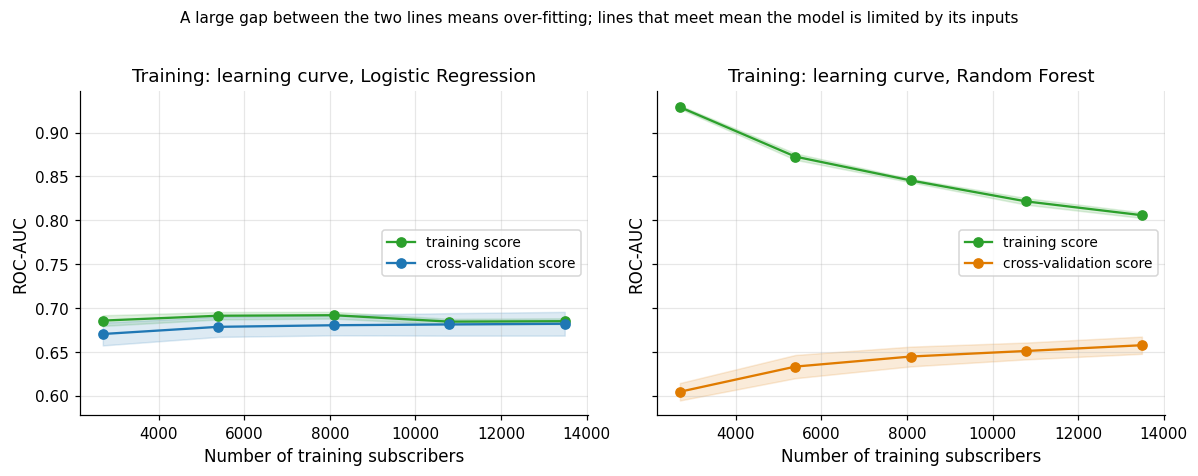

In [22]:
# ---- 5.2 TRAINING: learning curves ----------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
sizes = np.linspace(0.2, 1.0, 5)
for ax, k in zip(axes, KEYS):
    ts, tr_s, te_s = learning_curve(build_pipeline(k), X_train, y_train, cv=cv, scoring="roc_auc",
                                    train_sizes=sizes, n_jobs=1)
    for scores, lab, col in [(tr_s, "training score", "#2ca02c"), (te_s, "cross-validation score", COLORS[k])]:
        ax.plot(ts, scores.mean(axis=1), "o-", color=col, label=lab)
        ax.fill_between(ts, scores.mean(axis=1) - scores.std(axis=1), scores.mean(axis=1) + scores.std(axis=1), color=col, alpha=0.15)
    ax.set_title(f"Training: learning curve, {SHORT[k]}")
    ax.set_xlabel("Number of training subscribers"); ax.set_ylabel("ROC-AUC"); ax.legend(loc="center right")
fig.suptitle("A large gap between the two lines means over-fitting; lines that meet mean the model is limited by its inputs", fontsize=10, y=1.02)
fig.tight_layout(); save_fig(fig, "ss3_fig2_training_learning_curves.png")
plt.show()

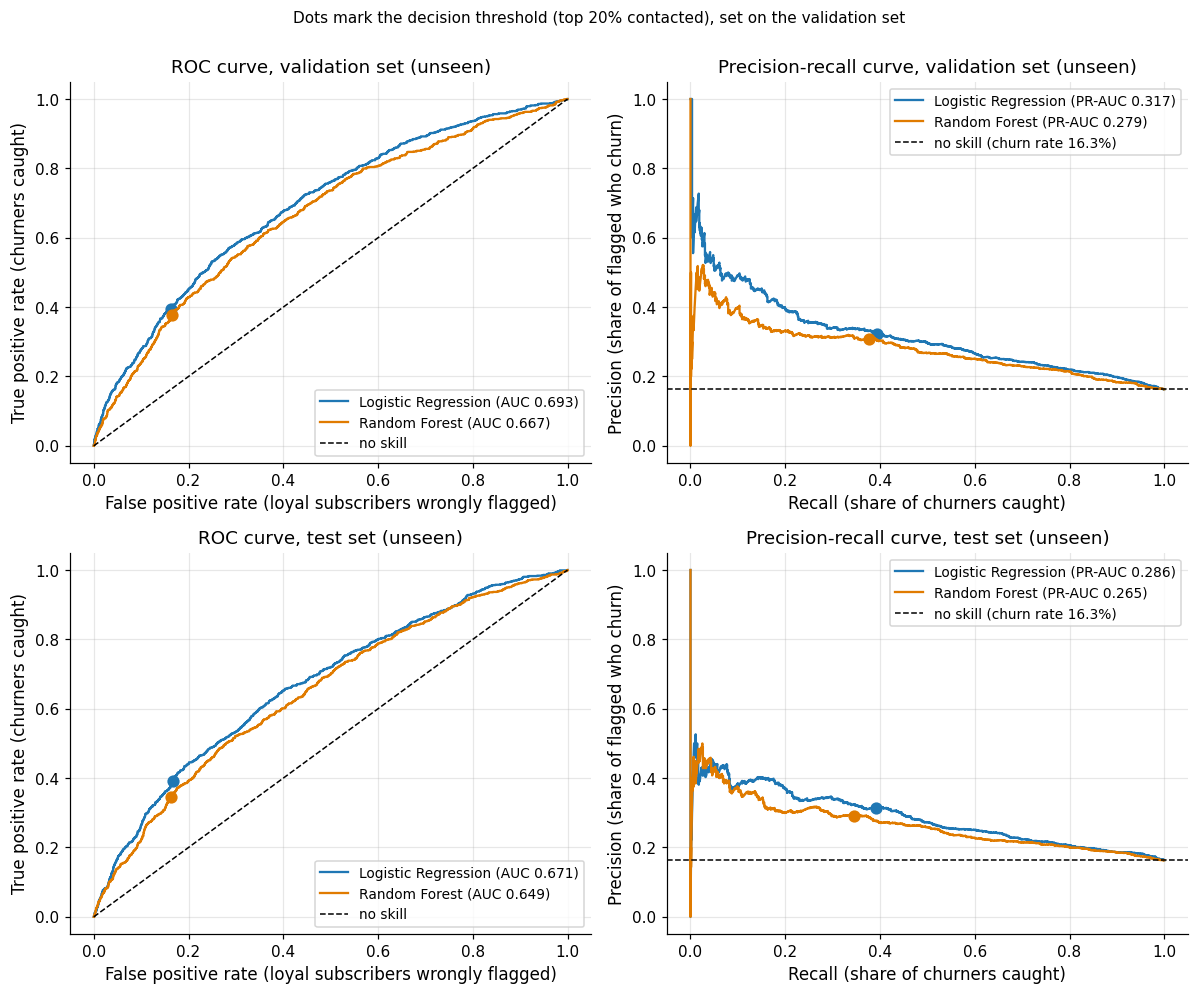

In [23]:
# ---- 5.3 UNSEEN: ROC and precision-recall curves on validation and test ---------------------
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for r, (split, y_s, label) in enumerate([("val", y_val, "validation set (unseen)"), ("test", y_test, "test set (unseen)")]):
    ax_roc, ax_pr = axes[r]
    for k in KEYS:
        p = proba[split][k]
        fpr, tpr, _ = roc_curve(y_s, p); pr, rc, _ = precision_recall_curve(y_s, p)
        pm = point_metrics(y_s, p, thr[k])
        auc, ap = roc_auc_score(y_s, p), average_precision_score(y_s, p)
        ax_roc.plot(fpr, tpr, color=COLORS[k], label=f"{SHORT[k]} (AUC {auc:.3f})")
        ax_roc.plot(pm["fp"] / (pm["fp"] + pm["tn"]), pm["recall"], "o", color=COLORS[k], ms=7)
        ax_pr.plot(rc, pr, color=COLORS[k], label=f"{SHORT[k]} (PR-AUC {ap:.3f})")
        ax_pr.plot(pm["recall"], pm["precision"], "o", color=COLORS[k], ms=7)
    ax_roc.plot([0, 1], [0, 1], "k--", lw=1, label="no skill")
    ax_roc.set_xlabel("False positive rate (loyal subscribers wrongly flagged)"); ax_roc.set_ylabel("True positive rate (churners caught)")
    ax_roc.set_title(f"ROC curve, {label}"); ax_roc.legend(loc="lower right")
    ax_pr.axhline(y_s.mean(), color="k", ls="--", lw=1, label=f"no skill (churn rate {y_s.mean():.1%})")
    ax_pr.set_xlabel("Recall (share of churners caught)"); ax_pr.set_ylabel("Precision (share of flagged who churn)")
    ax_pr.set_title(f"Precision-recall curve, {label}"); ax_pr.legend(loc="upper right")
fig.suptitle(f"Dots mark the decision threshold (top {TOP}% contacted), set on the validation set", fontsize=10, y=1.0)
fig.tight_layout(); save_fig(fig, "ss3_fig3_unseen_roc_pr_curves.png")
plt.show()

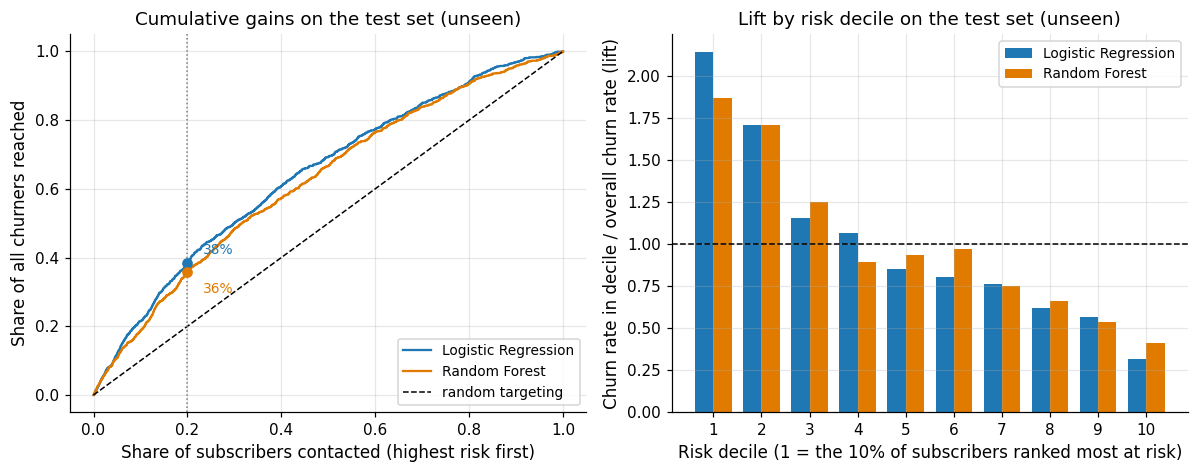

In [24]:
# ---- 5.4 UNSEEN: cumulative gains and lift by risk decile (test set) -----------------------------
def gains_curve(y, p):
    order = np.argsort(-p)
    cum = np.cumsum(y[order]) / y.sum()
    share = np.arange(1, len(y) + 1) / len(y)
    return share, cum

def decile_lift(y, p):
    order = np.argsort(-p)
    groups = np.array_split(y[order], 10)
    return np.array([g.mean() for g in groups]) / y.mean()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
ax = axes[0]
for k in KEYS:
    s, c = gains_curve(y_test, proba["test"][k]); ax.plot(s, c, color=COLORS[k], label=SHORT[k])
ax.plot([0, 1], [0, 1], "k--", lw=1, label="random targeting")
ax.axvline(CONTACT_FRACTION, color="grey", ls=":", lw=1)
gain_at_contact = {}
for k, offset in zip(KEYS, [(10, 6), (10, -14)]):
    s, c = gains_curve(y_test, proba["test"][k]); v = c[int(CONTACT_FRACTION * len(c)) - 1]
    gain_at_contact[k] = float(v)
    ax.plot(CONTACT_FRACTION, v, "o", color=COLORS[k])
    ax.annotate(f"{v:.0%}", (CONTACT_FRACTION, v), textcoords="offset points", xytext=offset, fontsize=9, color=COLORS[k])
ax.set_xlabel("Share of subscribers contacted (highest risk first)"); ax.set_ylabel("Share of all churners reached")
ax.set_title("Cumulative gains on the test set (unseen)"); ax.legend(loc="lower right")
ax = axes[1]
x = np.arange(1, 11); w = 0.38
for j, k in enumerate(KEYS):
    ax.bar(x + (j - 0.5) * w, decile_lift(y_test, proba["test"][k]), w, color=COLORS[k], label=SHORT[k])
ax.axhline(1, color="k", ls="--", lw=1)
ax.set_xticks(x); ax.set_xlabel("Risk decile (1 = the 10% of subscribers ranked most at risk)"); ax.set_ylabel("Churn rate in decile / overall churn rate (lift)")
ax.set_title("Lift by risk decile on the test set (unseen)"); ax.legend()
fig.tight_layout(); save_fig(fig, "ss3_fig4_unseen_gains_and_lift.png")
plt.show()

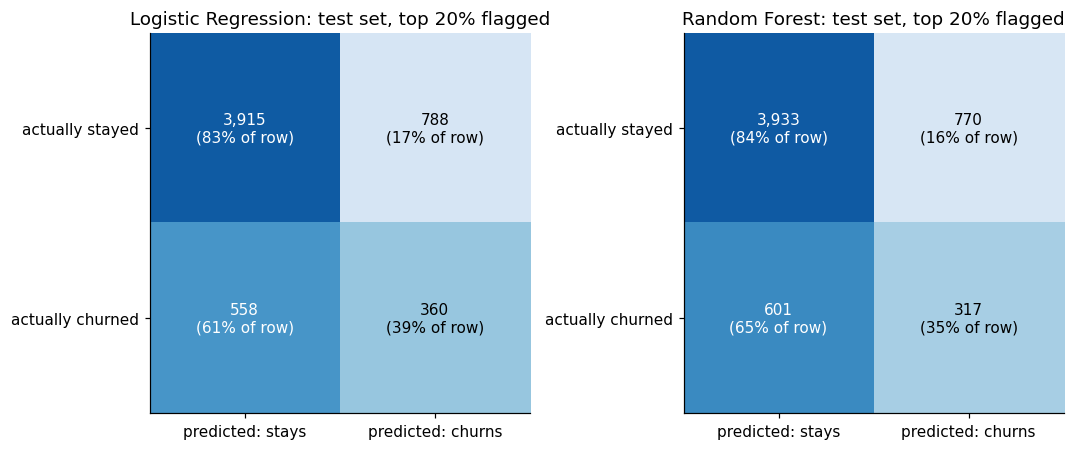

In [25]:
# ---- 5.5 UNSEEN: confusion matrices at the decision threshold (test set) --------------------------
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, k in zip(axes, KEYS):
    e = est_test[k]
    cm = np.array([[e["tn"], e["fp"]], [e["fn"], e["tp"]]])
    pct = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(pct, cmap="Blues", vmin=0, vmax=1); ax.grid(False)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n({pct[i, j]:.0%} of row)", ha="center", va="center",
                    color="white" if pct[i, j] > 0.5 else "black", fontsize=10)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["predicted: stays", "predicted: churns"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["actually stayed", "actually churned"])
    ax.set_title(f"{SHORT[k]}: test set, top {TOP}% flagged")
fig.tight_layout(); save_fig(fig, "ss3_fig5_unseen_confusion_matrices.png")
plt.show()

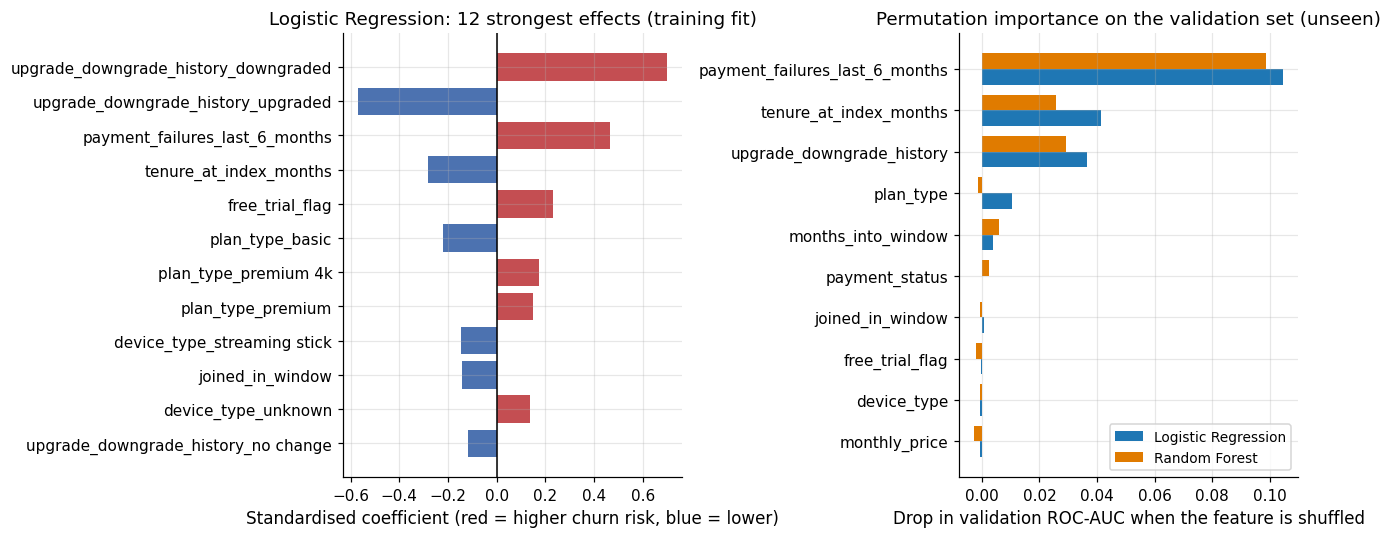

In [26]:
# ---- 5.6 What drives the predictions ---------------------------------------------------------------
lr_coef = effects.set_index("model_input")["logistic_regression_coefficient"]
lr_coef.index = lr_coef.index.str.replace(r"^(categorical|numeric|binary)__", "", regex=True)
top_coef = lr_coef.reindex(lr_coef.abs().sort_values(ascending=False).index).head(12).iloc[::-1]

perm = {}
for k in KEYS:
    r = permutation_importance(fitted[k], val[FEATURES], y_val, scoring="roc_auc", n_repeats=5, random_state=SEED, n_jobs=1)
    perm[k] = pd.Series(r.importances_mean, index=FEATURES)
perm_df = pd.DataFrame(perm)
order = perm_df.max(axis=1).sort_values(ascending=True).index

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ax = axes[0]
ax.barh(top_coef.index, top_coef.values, color=["#c44e52" if v > 0 else "#4c72b0" for v in top_coef.values])
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("Standardised coefficient (red = higher churn risk, blue = lower)")
ax.set_title("Logistic Regression: 12 strongest effects (training fit)")
ax = axes[1]
y_pos = np.arange(len(order)); h = 0.38
for j, k in enumerate(KEYS):
    ax.barh(y_pos + (j - 0.5) * h, perm_df.loc[order, k], h, color=COLORS[k], label=SHORT[k])
ax.set_yticks(y_pos); ax.set_yticklabels(order)
ax.set_xlabel("Drop in validation ROC-AUC when the feature is shuffled")
ax.set_title("Permutation importance on the validation set (unseen)"); ax.legend()
fig.tight_layout(); save_fig(fig, "ss3_fig6_what_drives_predictions.png")
plt.show()

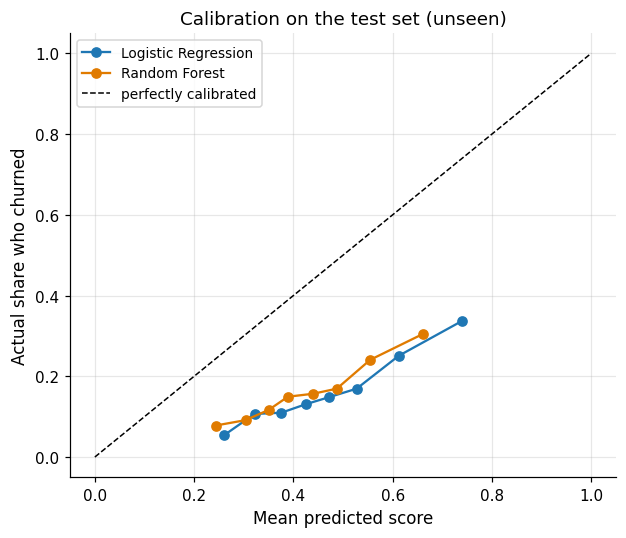

In [27]:
# ---- 5.7 How trustworthy are the scores? Calibration on the test set -------------------------------------
fig, ax = plt.subplots(figsize=(5.8, 5))
for k in KEYS:
    frac_pos, mean_pred = calibration_curve(y_test, proba["test"][k], n_bins=8, strategy="quantile")
    ax.plot(mean_pred, frac_pos, "o-", color=COLORS[k], label=SHORT[k])
ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfectly calibrated")
ax.set_xlabel("Mean predicted score"); ax.set_ylabel("Actual share who churned")
ax.set_title("Calibration on the test set (unseen)"); ax.legend(loc="upper left")
fig.tight_layout(); save_fig(fig, "ss3_fig7_unseen_calibration.png")
plt.show()

### 5.8 How to read the figures

* **Training (figures 1 and 2).** The Random Forest does much better on the data it was trained on than on held-out folds (gap 0.133), while Logistic Regression's two scores are close (gap 0.003). The learning curves show the same thing: the forest's two lines stay far apart (over-fitting), while the Logistic Regression lines meet at a modest level, which shows that the limit is the information in the inputs, not the choice of algorithm.
* **Unseen data (figures 3 to 5).** The curves sit above the "no skill" lines, so both models carry real information about who will churn, but the gap is modest. The gains and lift plots translate this into the business question: the first risk deciles contain clearly more churners than the later ones, so contacting the highest-risk subscribers first is better than contacting at random. A small note on numbers: the gains curve ranks the test subscribers directly, so at exactly 20% contacted it shows 38% for the final model, while section 4.6 reports 39.2% because it uses the threshold fixed on the validation set, which flags 20.4% of the test subscribers. They describe the same thing.
* **What drives the predictions (figure 6).** The most important inputs for the final model (Logistic Regression (Model 1)) are **payment_failures_last_6_months**, **tenure_at_index_months** and **upgrade_downgrade_history**. In the Logistic Regression, a **downgrade** and **more failed payments** go with higher churn risk, while an **upgrade** and a **longer tenure** go with lower risk. These describe association, not cause: a feature can predict churn without being the reason subscribers leave.
* **Calibration (figure 7).** The scores are far from the diagonal because both models use `class_weight="balanced"`: for the final model, the group with the highest scores has an average score of 0.74, but only 34% of them actually cancel. The scores are good for *ranking* subscribers, but they must not be read as a chance of cancelling.

Figures saved in `experimental_results/`: ss3_fig1_training_cv_seen_vs_unseen.png, ss3_fig2_training_learning_curves.png, ss3_fig3_unseen_roc_pr_curves.png, ss3_fig4_unseen_gains_and_lift.png, ss3_fig5_unseen_confusion_matrices.png, ss3_fig6_what_drives_predictions.png, ss3_fig7_unseen_calibration.png.

### Summary

The SS2 models were applied to the real STADIOchoice data. The client's data contains columns that reveal the outcome, so they were identified with evidence (section 2.5) and removed. On the honest feature set, Logistic Regression (Model 1) was selected by a rule fixed beforehand, and it ranks subscribers better than random, with confidence intervals reported on every metric. It is a modest first model; the clearest route to a much better one is a fixed-date extract that includes engagement data recorded before subscribers decide to leave.